In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Generating the network

In [4]:
N = 1024
m = 2
k = 5

In [5]:
P = np.array([[0.59, 0.43], [0.43, 0.78]])
l = np.array([0.25, 0.75])

In [6]:
generator = MultifractalNetworkGenerator(P,l,k,N,num_workers=-1)

Initializing...
0.0008721351623535156


In [45]:
generator()
print(2 * generator.G.number_of_edges() / generator.G.number_of_nodes())

Initializing...
0.001005411148071289
Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 138.17it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 77.80it/s]

Refining 1 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 77.13it/s]

... (27 outputs left out)


100%|██████████| 32/32 [00:00<00:00, 74.73it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 73.58it/s]

111.177734375


Calculating betweenness...
Done.
Calculating node positions...
Done.


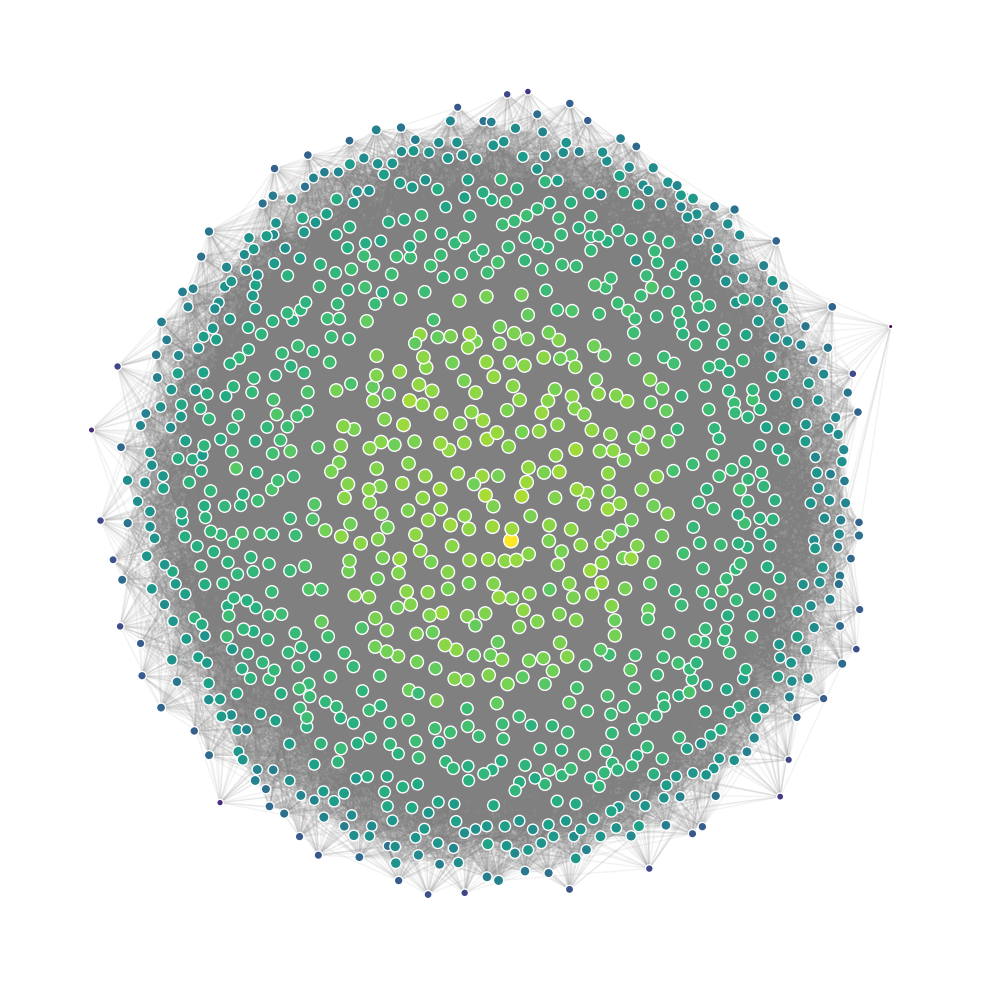

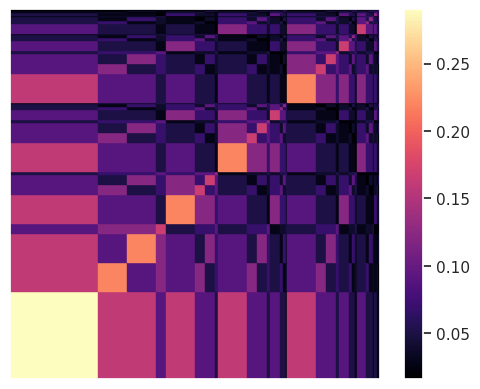

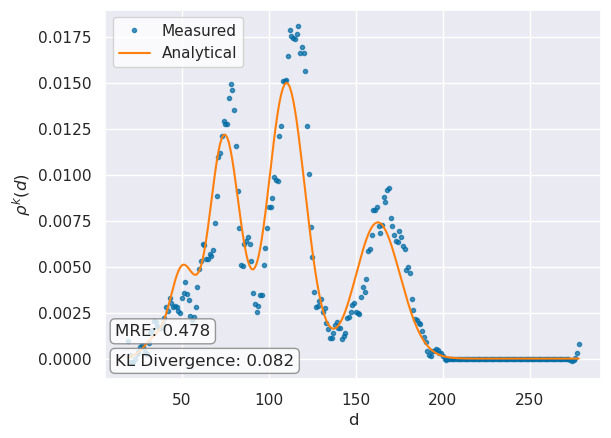

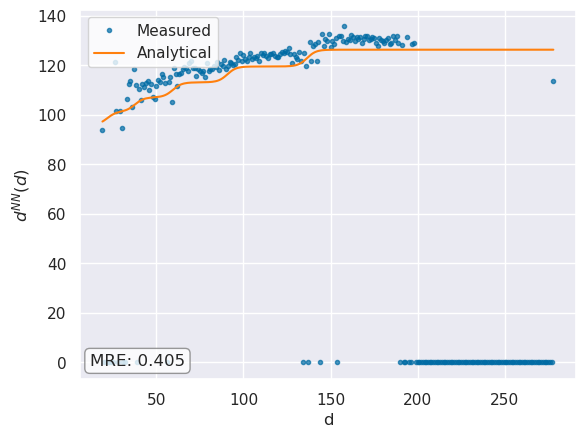

Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:20.121618
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:54:20.038351


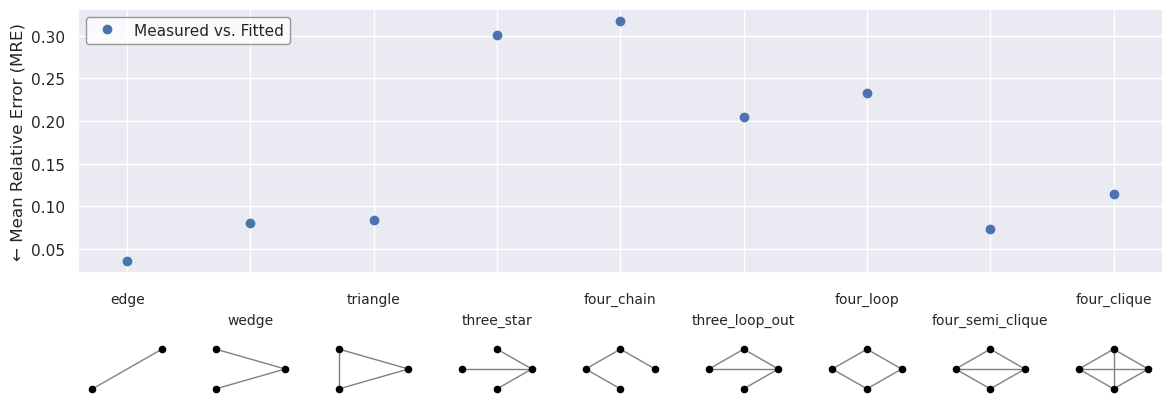

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'analytical_count': 54880.31575659009,
  'count': 56923,
  'MRE': 0.03588504195860916},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'analytical_count': 6580710.350378295,
  'count': 6052444,
  'MRE': 0.08027497371129969},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'analytical_count': 304876.6618656895,
  'count': 332737,
  'MRE': 0.08373080881991032},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'analytical_count': 286657978.81376827,
  'count': 200435629,
  'MRE': 0.3007847546074548},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'analytical_count': 799355175.2904582,
  'count': 545864993,


In [9]:
generator.plot_generated_network(
    layout_func = nx.kamada_kawai_layout,
    largest_component_only = False,
)

generator.network_stats(
    filename = "figures/synthetic_network_1k_plot_ground_truth.pdf",
    motif_analyzer_args = {
        'exact': True,
        'bootstrap_iters': None,
        'ci': None
    }
)

generator.motifs

In [47]:
generator.save_network('./test_networks/synthetic_network_1k.graphml')

# Fitting

## Load, count motifs

In [4]:
filename = './test_networks/synthetic_network_1k.graphml'
G = nx.read_graphml(filename)

In [5]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size**2))+1)

2  k_max:  6
3  k_max:  4
5  k_max:  3
6  k_max:  2
7  k_max:  2


In [6]:
mfnf = MultifractalNetworkFitter(G,
                                 d_range = [1,200],
                                 motifs = [
                                     {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
                                     {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
                                     {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
                                     {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
                                 ],
                                 sampling_ratios = {3: None,
                                                    4: None},
                                 motif_analyzer_args={'exact': True, 'bootstrap_iters': None, 'ci': None},
                                 population_size = 100,
                                 weights = {'rho':9,
                                            'deg_nn':9,
                                            'motifs':1,
                                            'edge':9},
                                 pre_loaded_motifs = './test_networks/synthetic_network_1k_motifs.pkl'
                                )

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Succesfully loaded motifs for network G from ./test_networks/synthetic_network_1k_motifs.pkl


In [7]:
P = np.array([[0.59, 0.43], [0.43, 0.78]])
l = np.array([0.25, 0.75])
k = 5
mfnf.set_ground_truth(P = P, l = l, k = k)

In [64]:
mfnf.save_motifs('./test_networks/synthetic_network_1k_motifs.pkl')

## Grid Search - Find m,k,P,l together

In [8]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,   'k': [1,6]},
                {'m': 3,   'k': [1,4]},
               ],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'energy'
)

[I 2025-02-20 13:21:20,780] A new study created in memory with name: no-name-36085495-7f2f-4a7e-89de-da588aa06746


Grid Search requires 5 trials...


[I 2025-02-20 13:21:28,181] Trial 0 finished with value: 5.111543843259568 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 5.111543843259568.
[I 2025-02-20 13:21:35,319] Trial 1 finished with value: 7.5534820806105225 and parameters: {'m': 2, 'k': 1}. Best is trial 0 with value: 5.111543843259568.
[I 2025-02-20 13:21:43,270] Trial 2 finished with value: 5.757190226701107 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 5.111543843259568.
[I 2025-02-20 13:21:51,068] Trial 3 finished with value: 4.74279590902905 and parameters: {'m': 2, 'k': 4}. Best is trial 3 with value: 4.74279590902905.
[I 2025-02-20 13:21:58,457] Trial 4 finished with value: 4.487012391609528 and parameters: {'m': 2, 'k': 5}. Best is trial 4 with value: 4.487012391609528.
[I 2025-02-20 13:21:58,459] A new study created in memory with name: no-name-ab105c51-8838-4772-b971-c80846f36d88


Grid Search requires 3 trials...


[I 2025-02-20 13:22:12,421] Trial 0 finished with value: 4.597378076699513 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 4.597378076699513.
[I 2025-02-20 13:22:27,845] Trial 1 finished with value: 4.6303737910091725 and parameters: {'m': 3, 'k': 2}. Best is trial 0 with value: 4.597378076699513.
[I 2025-02-20 13:22:45,053] Trial 2 finished with value: 6.176331291541565 and parameters: {'m': 3, 'k': 1}. Best is trial 0 with value: 4.597378076699513.


Best parameters:  {'m': 2, 'k': 5}
Best energy:  4.487012391609528
Best KL-divergence:  0.03217776505812425
Best KLD augumented energy: 2.2044508115647012
Best P matrix:
 [[0.77752725 0.43715286]
 [0.43715286 0.5563262 ]]
Best l vector:
 [0.75920103 0.24079897]


---

In [9]:
import pickle
with open('./test_networks/synthetic_network_1k_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

### 2-5

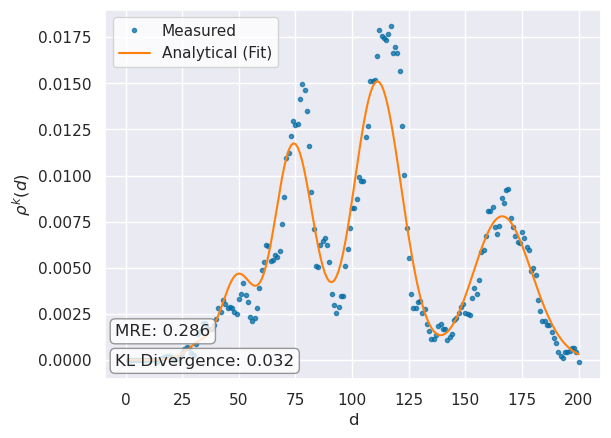

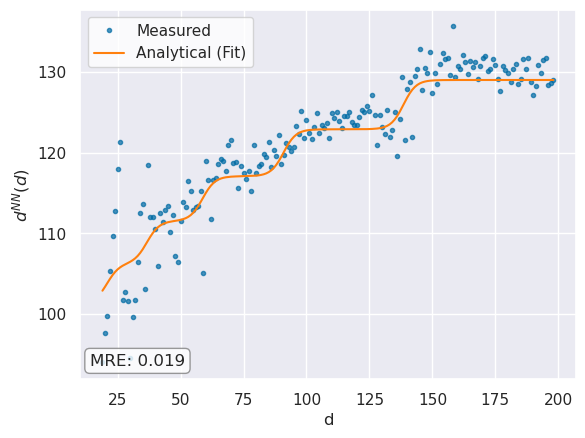

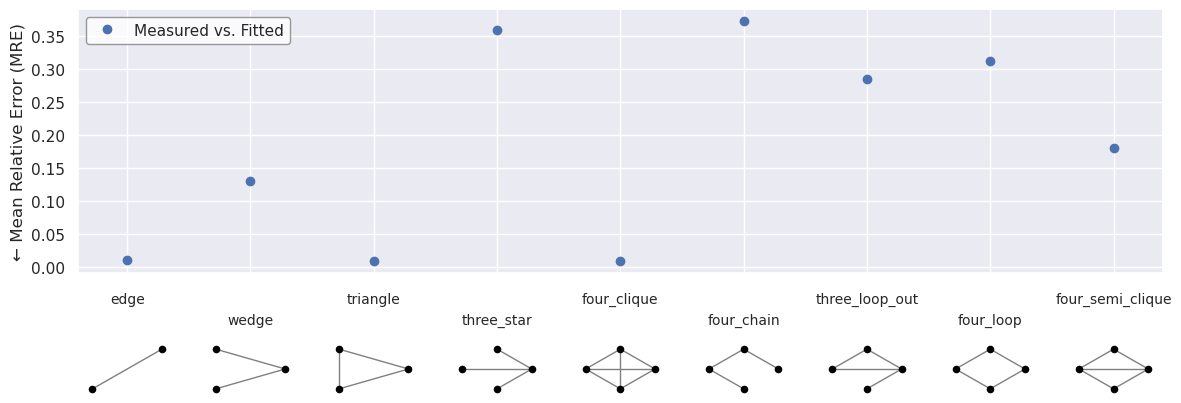

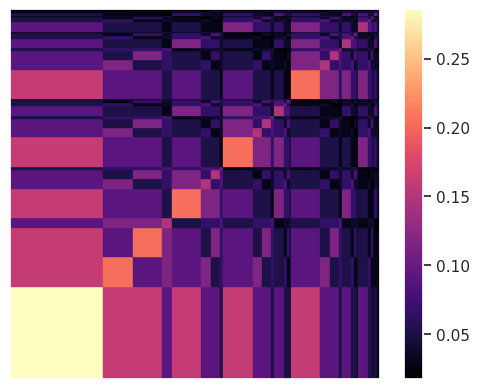

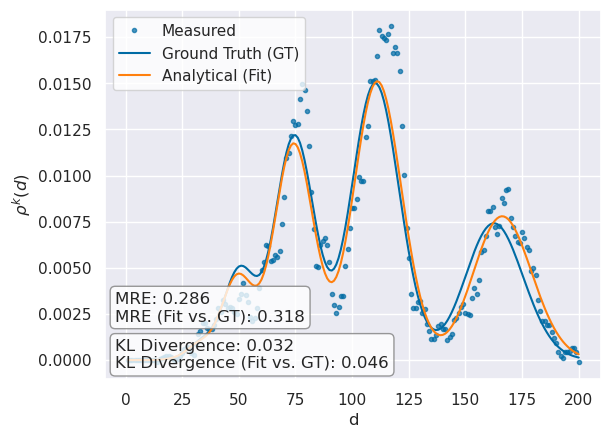

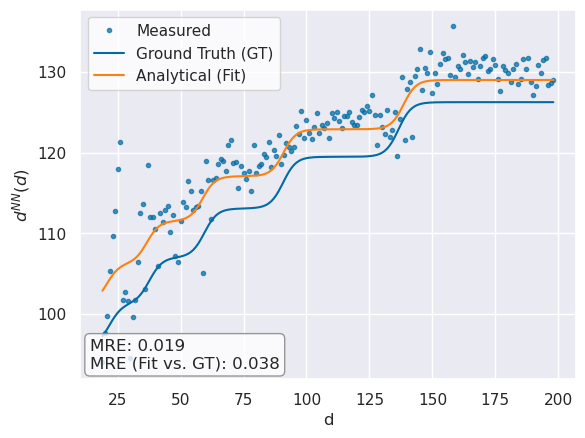

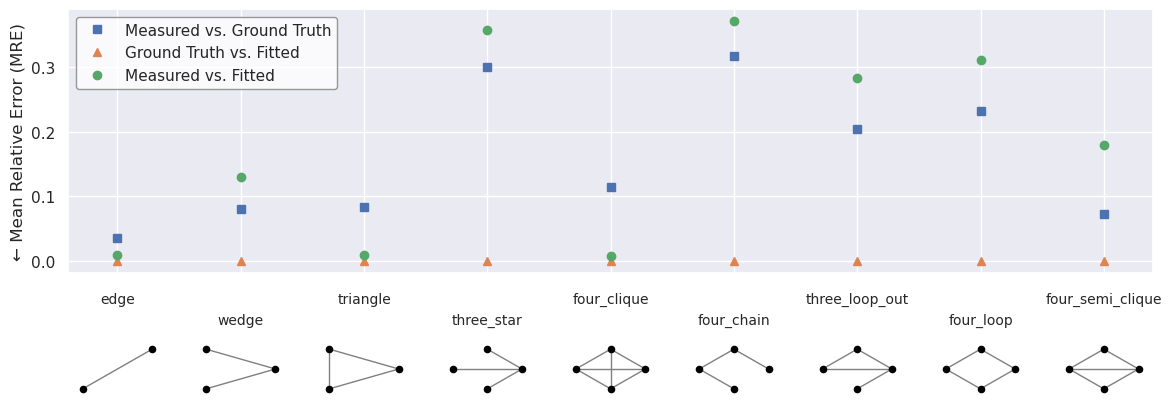

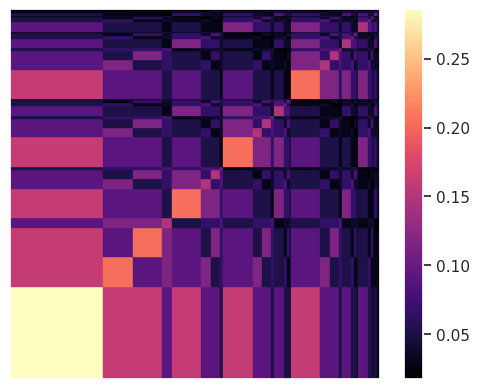

In [10]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_5.pdf"
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_5_gt.pdf"
)

#### Bootstrapping

In [11]:
M = 2
K = 5
mfnf.find_P_l(m = M, k = K, one_shot=True)
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size * 10,
    ci = 0.95,
    medoid = 'median'
)

Energy: 4.731463754928032
KL-divergence: 0.03569375684779675
KLD augumented energy: 2.4320330020312744
Gathering statistics (300 runs)...


100%|██████████| 300/300 [44:37<00:00,  8.93s/it]

Bootstrapping: Resampling 1000 times...


Bootstrapping finished in 0:00:00.527053
Energy = 4.58 (4.48, 4.77)
l = [0.75 (0.74, 0.77), 0.25 (0.23, 0.26)]
P = [
[0.78 (0.77, 0.79), 0.44 (0.42, 0.48)],

[0.44 (0.42, 0.48), 0.54 (0.43, 0.62)]
]


In [12]:
with open('./test_networks/synthetic_network_1k_2_5_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

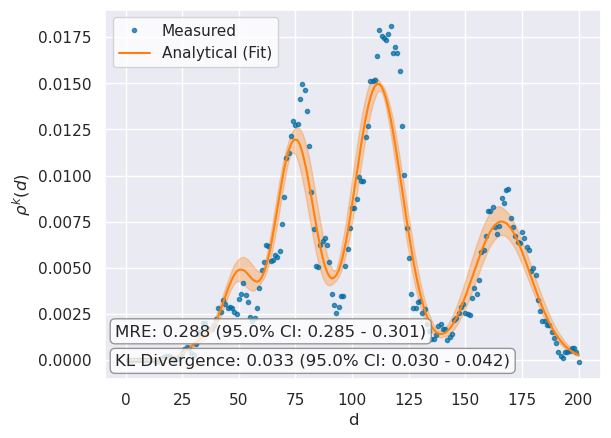

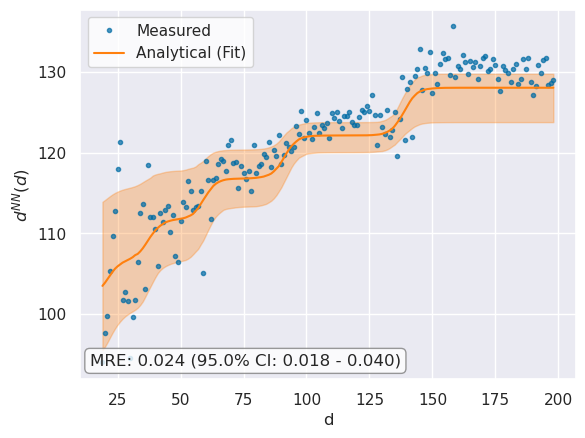

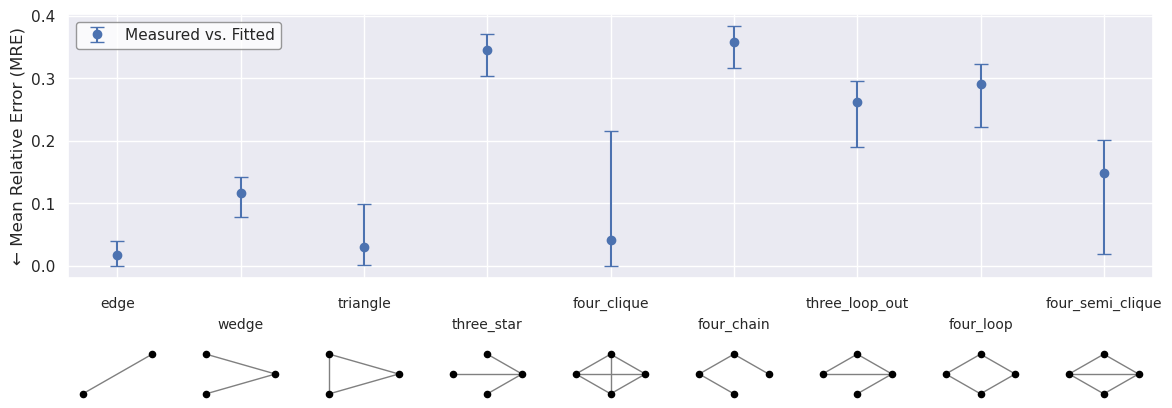

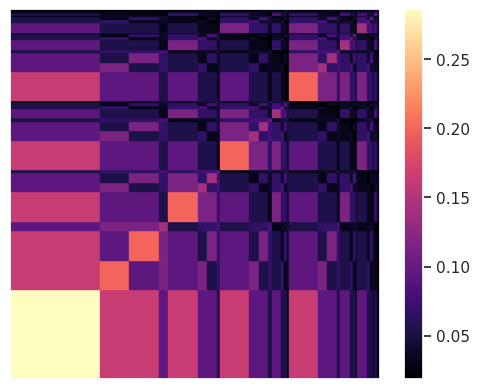

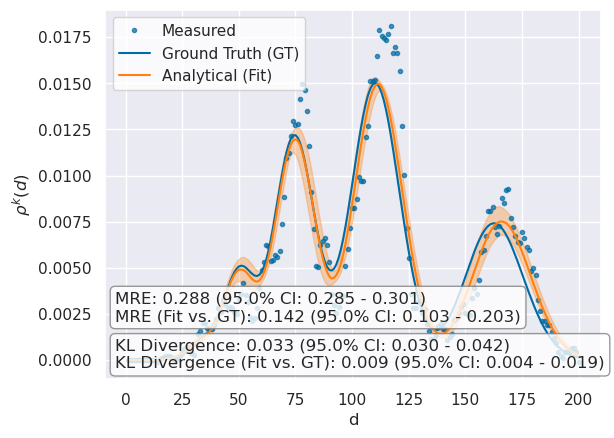

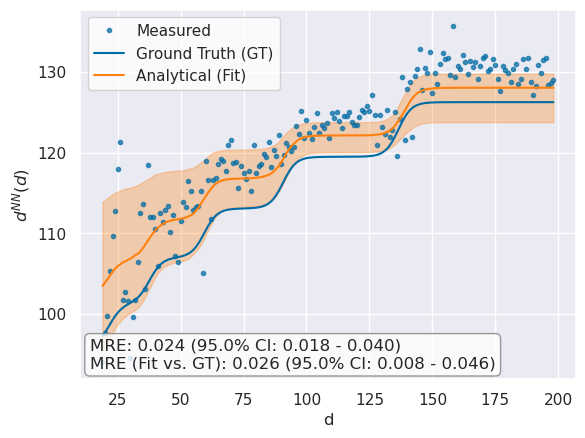

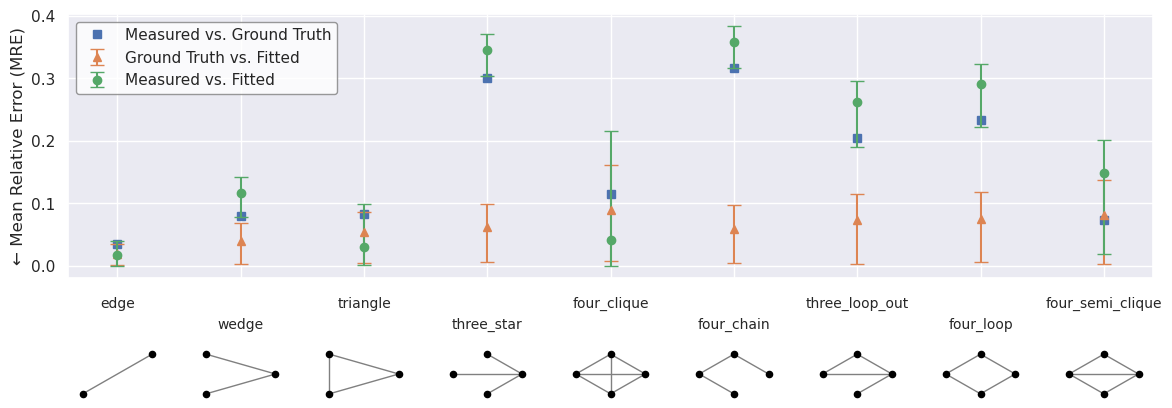

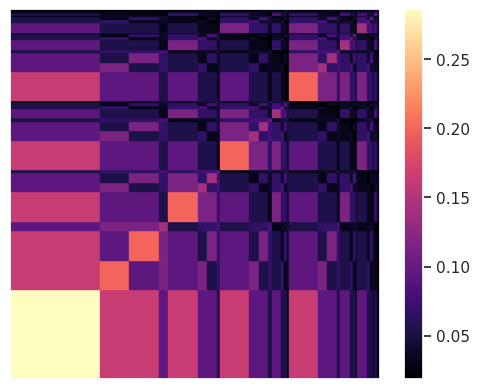

In [13]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_5_bootstrap.pdf"
)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_ground_truth=True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_1k_plot_2_5_bootstrap_gt.pdf"
)

---

## Variant Generation

In [15]:
M = 2
K = 5
mfnf.population_size = 500
mfnf.find_P_l(m = M, k = K, one_shot=True)

Energy: 4.530097198675188
KL-divergence: 0.031413092781724966
KLD augumented energy: 2.245689987878117


Initializing...
0.0009064674377441406
Calculating betweenness...
Done.
Calculating node positions...
Done.


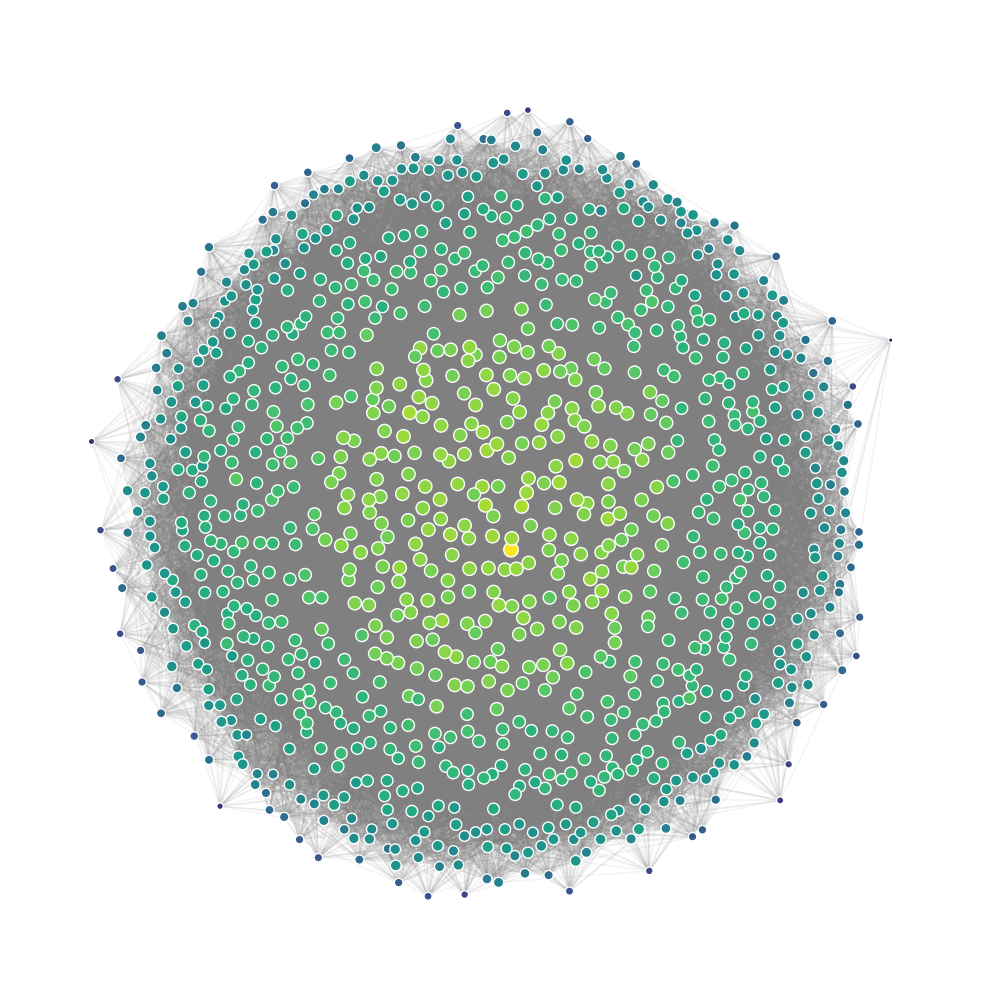

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 144.15it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


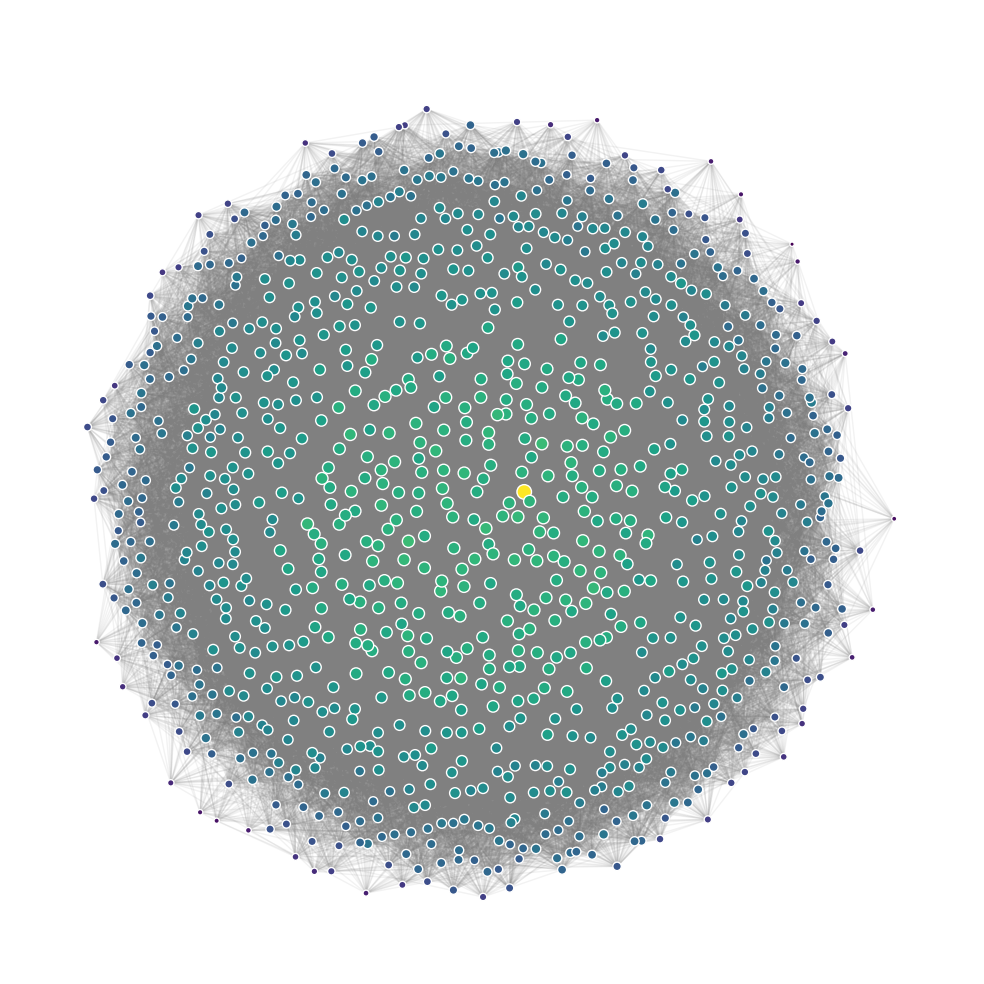

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 120.67it/s]


Refining network structure...
Calculating betweenness...
Done.
Calculating node positions...
Done.


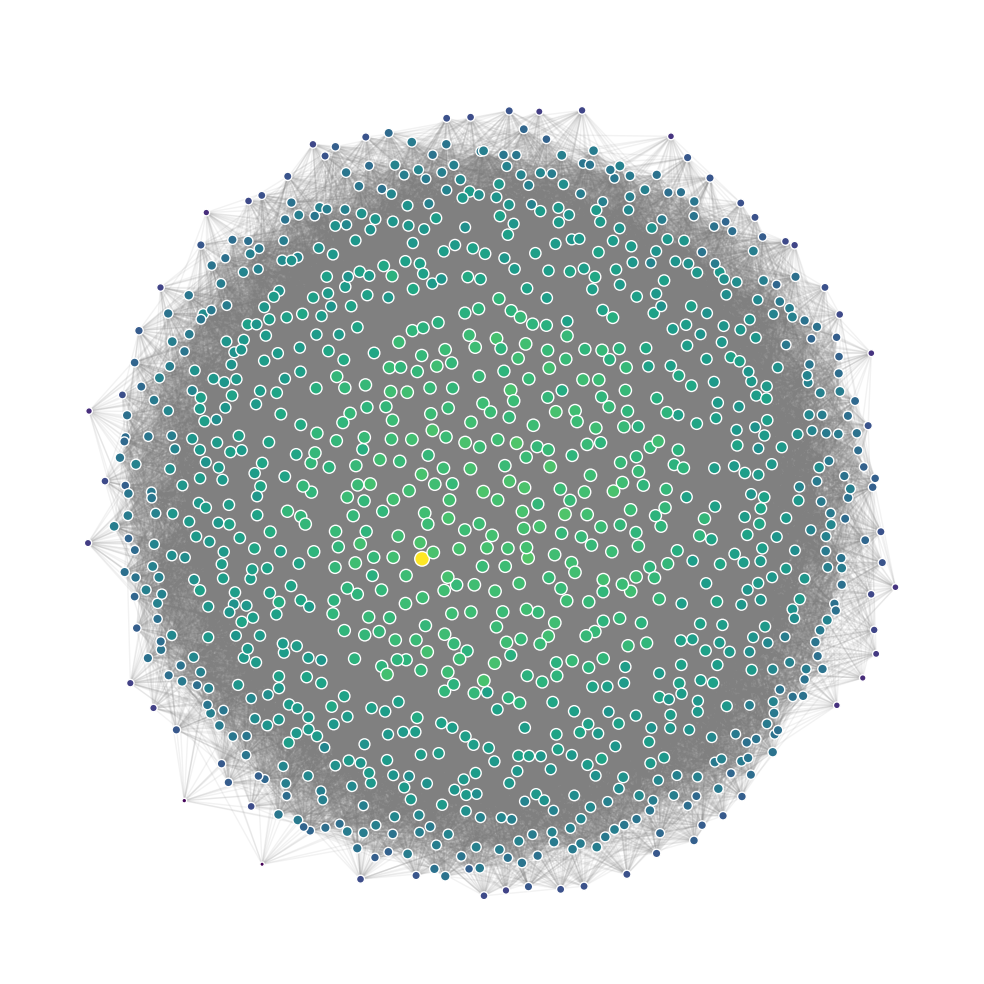

In [16]:
mfnf.generate_variants(
    number_of_variants = 2,
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  "figures/synthetic_network_1k_variants.pdf"
    },
    filename = "variant_networks/synthetic_network_1k_variants.graphml"
)